In [1]:
# imports and folders
import os, re
import numpy as np
import pandas as pd

DATA_DIR = r"E:\Pyhton code\Data Sets\daily mail text dataset"      # <-- folder where the dataset files are (or will be saved)

PROCESSED_DIR = os.path.join(os.getcwd(), "processed_data")
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(PROCESSED_DIR, exist_ok=True)

SEED = 42
print("Data folder     :", DATA_DIR)
print("Processed folder:", PROCESSED_DIR)

Data folder     : E:\Pyhton code\Data Sets\daily mail text dataset
Processed folder: e:\Pyhton code\Deep Learning\Natural Language Processing (NLP)\article text summarization\processed_data


In [2]:
# load every files from folder
def split_of(name):
    n = name.lower()
    if "train" in n: return "train"
    if "valid" in n or n.startswith("val"): return "validation"
    if "test" in n: return "test"
    return None

frames = {"train": [], "validation": [], "test": []}
for root, _, files in os.walk(DATA_DIR):
    if "1.0.0" in root or "2.0.0" in root:
        continue
    for f in sorted(files):
        if not f.lower().endswith(".parquet"):
            continue
        s = split_of(f) or split_of(os.path.basename(root))
        if s is None:
            print("Skipped (split unknown):", f)
            continue
        frames[s].append(pd.read_parquet(os.path.join(root, f)))
        print(f"{s:11s} {os.path.relpath(os.path.join(root, f), DATA_DIR)}")

def to_pair(df):
    cols = {c.lower(): c for c in df.columns}
    a = cols.get("article") or cols.get("document") or cols.get("text")
    s = cols.get("highlights") or cols.get("summary")
    if not (a and s):
        raise ValueError(f"Could not find article and summary columns in: {list(df.columns)}")
    return df[[a, s]].rename(columns={a: "article", s: "summary"})

raw = {s: to_pair(pd.concat(v, ignore_index=True)) for s, v in frames.items() if v}
print()
for s, d in raw.items():
    print(f"{s:11s} {len(d):>8,} articles")

test        test-00000-of-00001.parquet
train       train-00001-of-00003.parquet
validation  validation-00000-of-00001.parquet

train         95,704 articles
validation    13,368 articles
test          11,490 articles


In [3]:
# basic checks and a first look
d = raw["train"]
print("Nulls            :", d.isnull().sum().to_dict())
print("Duplicate articles:", f"{d['article'].duplicated().sum():,}")
print()
pd.set_option("display.max_colwidth", 400)
for i in [0, 1, 2]:
    print("ARTICLE (first 500 chars):", d["article"].iloc[i][:500])
    print("SUMMARY                  :", repr(d["summary"].iloc[i]))
    print()

Nulls            : {'article': 0, 'summary': 0}
Duplicate articles: 2

ARTICLE (first 500 chars): By . Daily Mail Reporter . PUBLISHED: . 04:03 EST, 3 August 2012 . | . UPDATED: . 08:07 EST, 3 August 2012 . A Texas Air Force basic training instructor has been sentenced to 30 days of confinement and reduction in rank for his part in a sex scandal at one of the busiest military training centers in America. Technical Sergeant Christopher Smith wooed one female trainee and fraternized with another at the Lackland Air Force base in San Antonio which has become the centre of an ongoing sex scandal
SUMMARY                  : "Lackland Air Force Base instructor Christopher Smith had inappropriate relations with two female trainees . Part of ongoing investigation at the base where 'at least 38 female trainees were victimized' 15 instructors implicated in the scandal - six of those have already been charged ."

ARTICLE (first 500 chars): By . Martin Robinson . PUBLISHED: . 10:45 EST, 2 August 20

       article_words  summary_words  summary_lines
count        20000.0        20000.0        20000.0
mean           707.5           51.4            1.0
std            316.3           22.3            0.0
min             77.0            5.0            1.0
50%            644.5           48.0            1.0
90%           1147.0           80.0            1.0
95%           1348.0           92.0            1.0
99%           1684.0          120.0            1.0
max           2019.0          346.0            1.0

Median summary / article length: 0.074


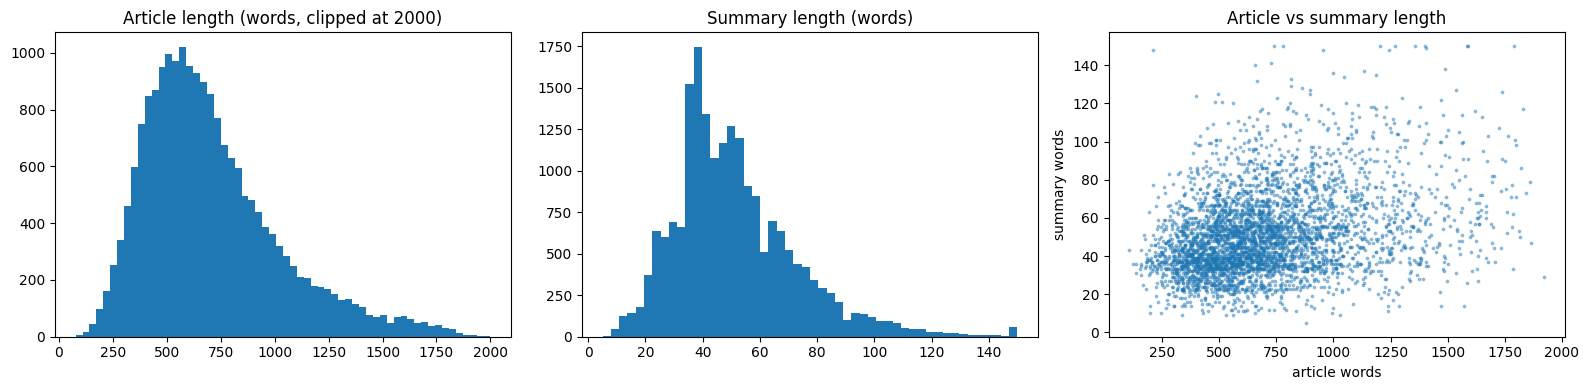

In [4]:
# length analysis
import matplotlib.pyplot as plt

sample = raw["train"].sample(20_000, random_state=SEED)
aw = sample["article"].str.split().str.len()
sw = sample["summary"].str.split().str.len()
lines = sample["summary"].str.count("\n") + 1

stats = pd.DataFrame({"article_words": aw, "summary_words": sw, "summary_lines": lines})
print(stats.describe(percentiles=[.5, .9, .95, .99]).round(1))
print("\nMedian summary / article length:", round((sw / aw).median(), 3))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(aw.clip(upper=2000), bins=60); ax[0].set_title("Article length (words, clipped at 2000)")
ax[1].hist(sw.clip(upper=150), bins=50);  ax[1].set_title("Summary length (words)")
ax[2].scatter(aw.clip(upper=2000)[:4000], sw.clip(upper=150)[:4000], s=3, alpha=0.4)
ax[2].set_title("Article vs summary length"); ax[2].set_xlabel("article words"); ax[2].set_ylabel("summary words")
plt.tight_layout(); plt.show()

In [5]:
# how much news boilerplate is there?
head = sample["article"].str[:300]
checks = {
    "contains (CNN)":        r"\(CNN\)",
    "starts with 'By .'":    r"^By \.",
    "contains PUBLISHED:":   r"PUBLISHED:",
    "contains UPDATED:":     r"UPDATED:",
    "contains Last updated": r"Last updated at",
}
for name, pat in checks.items():
    print(f"{name:25s} {head.str.contains(pat, regex=True).mean() * 100:5.1f}% of articles")

print("\nStart of 6 random articles:")
for t in sample["article"].sample(6, random_state=1):
    print("  >", t[:160].replace("\n", " "))

contains (CNN)              0.0% of articles
starts with 'By .'         97.2% of articles
contains PUBLISHED:        59.5% of articles
contains UPDATED:          60.9% of articles
contains Last updated       0.0% of articles

Start of 6 random articles:
  > By . Daily Mail Reporters . PUBLISHED: . 22:22 EST, 12 December 2013 . | . UPDATED: . 09:16 EST, 13 December 2013 . Home invasion survivor William Petit has had
  > By . Ruth Styles . PUBLISHED: . 06:49 EST, 12 June 2013 . | . UPDATED: . 18:37 EST, 12 June 2013 . The 1,082ft cruise ship set to be named by the Duchess of Cam
  > By . Ashley Collman . PUBLISHED: . 00:37 EST, 30 June 2013 . | . UPDATED: . 17:52 EST, 30 June 2013 . We've all seen the photos and images of Earth taken from s
  > By . Lucy Waterlow for MailOnline . A 20-year-old zoo keeper from Pembroke, Wales, has become the leader of a pride of lions. Rosie Badger will be responsible f
  > By . Emma Thomas . PUBLISHED: . 15:55 EST, 24 December 2013 . | . UPDATED: . 10:20

In [6]:
# cleaning functions and a before/after check
HEADER_PATTERNS = [
    re.compile(r"^.{0,150}?\(CNN\)\s*(?:--|-|—)?\s*"),
    re.compile(r"^By \. .{1,120}? \. (?:and .{1,80}? \. )?"),
    re.compile(r"^PUBLISHED: \. .{1,80}? \d{4} \. (?:\| \. )?(?:UPDATED: \. .{1,80}? \d{4} \. )?"),
    re.compile(r"^Last updated at .{1,80}? \d{4} \. "),
    re.compile(r"^UPDATED: \. .{1,80}? \d{4} \. "),
]

def clean_article(t):
    t = t.strip()
    for _ in range(2):                                   # the header can have several parts
        for p in HEADER_PATTERNS:
            t = p.sub("", t, count=1)
    return re.sub(r"\s+", " ", t).strip()

def clean_summary(t):
    t = re.sub(r"\s*\n\s*", " ", t.strip())              # join the highlight lines into one paragraph
    t = re.sub(r"\s+([.,!?;:%])", r"\1", t)              # "word ." -> "word."
    return re.sub(r"\s+", " ", t).strip()

# --- before / after on 6 articles ---
for t in sample["article"].sample(6, random_state=1):
    print("BEFORE:", t[:170].replace("\n", " "))
    print("AFTER :", clean_article(t)[:170])
    print()

for t in sample["summary"].sample(2, random_state=3):
    print("SUMMARY BEFORE:", repr(t))
    print("SUMMARY AFTER :", clean_summary(t))
    print()

changed = sample["article"].map(lambda t: clean_article(t) != re.sub(r"\s+", " ", t.strip())).mean() * 100
print(f"Articles changed by header cleaning: {changed:.1f}%")

BEFORE: By . Daily Mail Reporters . PUBLISHED: . 22:22 EST, 12 December 2013 . | . UPDATED: . 09:16 EST, 13 December 2013 . Home invasion survivor William Petit has had a wonderf
AFTER : Home invasion survivor William Petit has had a wonderful year and for the first time since 2007, he will be able to enjoy Christmas with one of his children. Dr Petit and

BEFORE: By . Ruth Styles . PUBLISHED: . 06:49 EST, 12 June 2013 . | . UPDATED: . 18:37 EST, 12 June 2013 . The 1,082ft cruise ship set to be named by the Duchess of Cambridge has
AFTER : The 1,082ft cruise ship set to be named by the Duchess of Cambridge has been unveiled ahead of today's launch with a set of images that reveal the lavish interior and imp

BEFORE: By . Ashley Collman . PUBLISHED: . 00:37 EST, 30 June 2013 . | . UPDATED: . 17:52 EST, 30 June 2013 . We've all seen the photos and images of Earth taken from space while
AFTER : We've all seen the photos and images of Earth taken from space while space stations orbit our h

In [7]:
#clean all splits
def prepare(df, name):
    n0 = len(df)
    out = pd.DataFrame({
        "article": df["article"].astype(str).map(clean_article),
        "summary": df["summary"].astype(str).map(clean_summary),
    })
    aw = out["article"].str.split().str.len()
    sw = out["summary"].str.split().str.len()
    out = out[(aw >= 50) & (sw >= 10) & (sw <= 150)]
    out = out.drop_duplicates(subset="article").reset_index(drop=True)
    print(f"{name:11s} {n0:>8,} -> {len(out):>8,}  (kept {len(out) / n0 * 100:.1f}%)")
    return out

clean = {s: prepare(df, s) for s, df in raw.items()}

train         95,704 ->   95,227  (kept 99.5%)
validation    13,368 ->   13,340  (kept 99.8%)
test          11,490 ->   11,463  (kept 99.8%)


In [8]:
# choose sizes and save
TRAIN_SIZE = 150_000     
VAL_SIZE   = 3_000       

train_df = clean["train"].sample(n=min(TRAIN_SIZE, len(clean["train"])), random_state=SEED).reset_index(drop=True)
val_df   = clean["validation"].sample(n=min(VAL_SIZE, len(clean["validation"])), random_state=SEED).reset_index(drop=True)
test_df  = clean["test"].reset_index(drop=True)

train_df.to_parquet(os.path.join(PROCESSED_DIR, "train.parquet"), index=False)
val_df.to_parquet(os.path.join(PROCESSED_DIR, "val.parquet"), index=False)
test_df.to_parquet(os.path.join(PROCESSED_DIR, "test.parquet"), index=False)

print("train:", f"{len(train_df):,}", "| val:", f"{len(val_df):,}", "| test:", f"{len(test_df):,}")
print("Saved in:", PROCESSED_DIR)

train: 95,227 | val: 3,000 | test: 11,463
Saved in: e:\Pyhton code\Deep Learning\Natural Language Processing (NLP)\article text summarization\processed_data


In [9]:
# verify and look at one clean pair
chk = pd.read_parquet(os.path.join(PROCESSED_DIR, "train.parquet"))
print(chk.shape)
print("\nARTICLE (first 600 chars):\n", chk["article"].iloc[0][:600])
print("\nSUMMARY:\n", chk["summary"].iloc[0])

(95227, 2)

ARTICLE (first 600 chars):
 At 800 ft up in the air, thrill seekers are jumping from cliff tops and walking along slack ropes in a giant 'playground' perfect for daredevils. Adrenaline junkies travel from all over the globe to test their skills at the spectacular location perfect for everything from climbing to skydiving, BASE jumping and slacklining. Discovered in the breath-taking Moab Desert in Utah, America, the Fisher Towers playground features vast terrain perfect for top climbers. Daredevil: Adrenaline junkie Andy Lewis balances on a slackline rope between the highest towers in Moab Desert, Echo and Cottontail, 80

SUMMARY:
 Moab Desert is a spectacular location for climbing, skydiving, base jumping and slacklining. The towers range from 35 to 800 ft high. Adventurers walk slacklines between towers and jump from cliffs 800 ft in the air.


In [10]:
# load the cleaned data
import os, re, time
import numpy as np
import pandas as pd
import sentencepiece as spm

BASE_DIR      = os.getcwd()
PROCESSED_DIR = os.path.join(BASE_DIR, "processed_data")
TOKENIZER_DIR = os.path.join(BASE_DIR, "tokenizer")
os.makedirs(TOKENIZER_DIR, exist_ok=True)

train_df = pd.read_parquet(os.path.join(PROCESSED_DIR, "train.parquet"))
val_df   = pd.read_parquet(os.path.join(PROCESSED_DIR, "val.parquet"))
test_df  = pd.read_parquet(os.path.join(PROCESSED_DIR, "test.parquet"))

print("train:", f"{len(train_df):,}", "| val:", f"{len(val_df):,}", "| test:", f"{len(test_df):,}")

train: 95,227 | val: 3,000 | test: 11,463


In [11]:
# write the tokenizer training text
corpus_path = os.path.join(TOKENIZER_DIR, "corpus.txt")
sent_split = re.compile(r"(?<=[.!?])\s+")

def write_sentences(f, texts):
    n = 0
    for text in texts:
        for s in sent_split.split(text):
            s = s.strip()
            if 10 <= len(s) <= 2000:
                f.write(s + "\n")
                n += 1
    return n

t0 = time.time()
with open(corpus_path, "w", encoding="utf-8") as f:
    n_art = write_sentences(f, train_df["article"].iloc[:40_000])
    n_sum = write_sentences(f, train_df["summary"])

print(f"Sentences from articles : {n_art:,}")
print(f"Sentences from summaries: {n_sum:,}")
print(f"Corpus size             : {os.path.getsize(corpus_path) / 1e6:.0f} MB  ({time.time() - t0:.0f}s)")

Sentences from articles : 1,487,499
Sentences from summaries: 342,733
Corpus size             : 189 MB  (10s)


In [12]:
#train the BPE tokenizer
VOCAB_SIZE = 16_000

spm.SentencePieceTrainer.train(
    input=corpus_path,
    model_prefix=os.path.join(TOKENIZER_DIR, "bpe"),
    vocab_size=VOCAB_SIZE,
    model_type="bpe",
    character_coverage=0.9995,
    byte_fallback=True,
    pad_id=0, unk_id=1, bos_id=2, eos_id=3,
    pad_piece="<pad>", unk_piece="<unk>", bos_piece="<bos>", eos_piece="<eos>",
    input_sentence_size=1_000_000,
    shuffle_input_sentence=True,
    num_threads=os.cpu_count(),
)
print("Saved:", [f for f in os.listdir(TOKENIZER_DIR) if f.startswith("bpe")])

Saved: ['bpe.model', 'bpe.vocab']


In [13]:
# test the tokenizer on news-style text
sp = spm.SentencePieceProcessor(model_file=os.path.join(TOKENIZER_DIR, "bpe.model"))
print("Vocab:", sp.get_piece_size(), "| pad, unk, bos, eos =", sp.pad_id(), sp.unk_id(), sp.bos_id(), sp.eos_id(), "\n")

tests = [
    "The Duchess of Cambridge named the 1,082ft cruise ship on Thursday.",
    "Dr Petit said the family would spend Christmas together in Connecticut.",
    "Researchers at the University of Toronto studied 12,345 drinkers (aged 18-25).",
    "He said: 'It was a wonderful year' - and £20million richer.",
]
for t in tests:
    ids = sp.encode(t)
    print("Text   :", t)
    print("Pieces :", sp.encode(t, out_type=str))
    print(f"Tokens : {len(ids)} | decodes back exactly: {sp.decode(ids) == t}\n")

Vocab: 16000 | pad, unk, bos, eos = 0 1 2 3 

Text   : The Duchess of Cambridge named the 1,082ft cruise ship on Thursday.
Pieces : ['▁The', '▁Duchess', '▁of', '▁Cambridge', '▁named', '▁the', '▁1,', '0', '8', '2', 'ft', '▁cruise', '▁ship', '▁on', '▁Thursday', '.']
Tokens : 16 | decodes back exactly: True

Text   : Dr Petit said the family would spend Christmas together in Connecticut.
Pieces : ['▁Dr', '▁Pet', 'it', '▁said', '▁the', '▁family', '▁would', '▁spend', '▁Christmas', '▁together', '▁in', '▁Connecticut', '.']
Tokens : 13 | decodes back exactly: True

Text   : Researchers at the University of Toronto studied 12,345 drinkers (aged 18-25).
Pieces : ['▁Researchers', '▁at', '▁the', '▁University', '▁of', '▁Toronto', '▁studied', '▁12,', '3', '45', '▁drink', 'ers', '▁(', 'aged', '▁18-', '25', ').']
Tokens : 17 | decodes back exactly: True

Text   : He said: 'It was a wonderful year' - and £20million richer.
Pieces : ['▁He', '▁said', ':', "▁'", 'It', '▁was', '▁a', '▁wonderful', '▁year', 

In [14]:
# token length analysis (5,00 full articles)
sample = train_df.sample(5_000, random_state=42)
art_len = np.array([len(x) for x in sp.encode(sample["article"].tolist())])
sum_len = np.array([len(x) for x in sp.encode(sample["summary"].tolist())])

stats = pd.DataFrame({"article_tokens": art_len, "summary_tokens": sum_len})
print(stats.describe(percentiles=[.5, .9, .95, .99]).round(0))

a_words = sample["article"].str.split().str.len().sum()
s_words = sample["summary"].str.split().str.len().sum()
print(f"\nTokens per word -> article: {art_len.sum() / a_words:.2f} | summary: {sum_len.sum() / s_words:.2f}")

unk = sum(x.count(sp.unk_id()) for x in sp.encode(sample["article"].tolist()))
print(f"Unknown tokens in articles: {unk} (byte fallback should make this 0)")

       article_tokens  summary_tokens
count          5000.0          5000.0
mean            907.0            65.0
std             419.0            27.0
min             100.0            11.0
50%             818.0            61.0
90%            1479.0           100.0
95%            1759.0           115.0
99%            2223.0           151.0
max            2700.0           230.0

Tokens per word -> article: 1.32 | summary: 1.37
Unknown tokens in articles: 0 (byte fallback should make this 0)


In [15]:
# how much does truncation cost?
cand_src = [256, 320, 400, 512, 640]
cand_tgt = [80, 100, 110, 128, 160]

def words(t):
    return set(re.findall(r"[a-z0-9]+", t.lower()))

sub = sample.iloc[:1500]
ids_list = sp.encode(sub["article"].tolist())
full_recall = np.mean([len(words(s) & words(a)) / max(len(words(s)), 1)
                       for s, a in zip(sub["summary"], sub["article"])])

print(f"{'MAX_SRC':>8} {'articles kept whole':>20} {'article tokens kept':>20} {'summary words found':>20}")
for N in cand_src:
    whole = (art_len <= N - 2).mean() * 100
    kept = np.minimum(art_len, N - 2).sum() / art_len.sum() * 100
    trunc_text = sp.decode([x[:N - 2] for x in ids_list])
    rec = np.mean([len(words(s) & words(t)) / max(len(words(s)), 1) for s, t in zip(sub["summary"], trunc_text)]) * 100
    print(f"{N:>8} {whole:>19.1f}% {kept:>19.1f}% {rec:>19.1f}%")
print(f"{'full':>8} {'100.0%':>20} {'100.0%':>20} {full_recall * 100:>19.1f}%")

print(f"\n{'MAX_TGT':>8} {'summaries kept whole':>22}")
for N in cand_tgt:
    print(f"{N:>8} {(sum_len <= N - 2).mean() * 100:>21.1f}%")

 MAX_SRC  articles kept whole  article tokens kept  summary words found
     256                 0.9%                28.0%                70.0%
     320                 2.2%                34.9%                74.1%
     400                 5.5%                43.4%                77.9%
     512                14.5%                54.6%                81.5%
     640                28.6%                65.7%                83.8%
    full               100.0%               100.0%                87.6%

 MAX_TGT   summaries kept whole
      80                  73.8%
     100                  89.2%
     110                  92.8%
     128                  96.9%
     160                  99.3%


In [16]:
# choose the lengths, the encode and save
MAX_SRC = 400      # article tokens fed to the encoder (including bos and eos)
MAX_TGT = 110      # summary tokens (including bos and eos)

def encode_texts(texts, max_len, char_cut=None, chunk=5000):
    out, truncated = [], 0
    for i in range(0, len(texts), chunk):
        part = texts[i:i + chunk]
        if char_cut:
            part = [t[:char_cut] for t in part]       # 4000 characters is about 900 tokens, plenty for MAX_SRC up to about 800
        for e in sp.encode(part):
            truncated += len(e) > max_len - 2
            out.append(np.array(e[:max_len - 2], dtype=np.int32))
    return out, truncated

for name, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    src, tr_s = encode_texts(df["article"].tolist(), MAX_SRC, char_cut=4000)
    tgt, tr_t = encode_texts(df["summary"].tolist(), MAX_TGT)
    pd.DataFrame({"src_ids": src, "tgt_ids": tgt}).to_parquet(
        os.path.join(PROCESSED_DIR, f"{name}_tok.parquet"), index=False)
    print(f"{name:5s}: {len(df):>6,} pairs | mean src {np.mean([len(x) for x in src]):.0f} tokens, "
          f"{tr_s / len(df) * 100:.1f}% truncated | mean tgt {np.mean([len(x) for x in tgt]):.0f} tokens, "
          f"{tr_t / len(df) * 100:.1f}% truncated")

train: 95,227 pairs | mean src 394 tokens, 94.3% truncated | mean tgt 64 tokens, 7.1% truncated
val  :  3,000 pairs | mean src 388 tokens, 88.8% truncated | mean tgt 71 tokens, 10.6% truncated
test : 11,463 pairs | mean src 389 tokens, 89.6% truncated | mean tgt 68 tokens, 8.2% truncated


In [17]:
# verify a saved pair
chk = pd.read_parquet(os.path.join(PROCESSED_DIR, "train_tok.parquet"))
row = chk.iloc[0]
print("src ids:", len(row["src_ids"]), "| tgt ids:", len(row["tgt_ids"]), "| type:", type(row["src_ids"]).__name__)
print("\nSOURCE (decoded, first 400 chars):\n", sp.decode(row["src_ids"].tolist())[:400])
print("\nTARGET (decoded):\n", sp.decode(row["tgt_ids"].tolist()))

src ids: 398 | tgt ids: 54 | type: ndarray

SOURCE (decoded, first 400 chars):
 At 800 ft up in the air, thrill seekers are jumping from cliff tops and walking along slack ropes in a giant 'playground' perfect for daredevils. Adrenaline junkies travel from all over the globe to test their skills at the spectacular location perfect for everything from climbing to skydiving, BASE jumping and slacklining. Discovered in the breath-taking Moab Desert in Utah, America, the Fisher T

TARGET (decoded):
 Moab Desert is a spectacular location for climbing, skydiving, base jumping and slacklining. The towers range from 35 to 800 ft high. Adventurers walk slacklines between towers and jump from cliffs 800 ft in the air.


In [18]:
# imports, load the encoded data, drop cut summaires
import json, random
import torch
from torch.utils.data import Dataset, DataLoader, Sampler
from torch.nn.utils.rnn import pad_sequence

PAD, UNK, BOS, EOS = sp.pad_id(), sp.unk_id(), sp.bos_id(), sp.eos_id()

def load_tok(name):
    d = pd.read_parquet(os.path.join(PROCESSED_DIR, f"{name}_tok.parquet"))
    return d["src_ids"].tolist(), d["tgt_ids"].tolist()

train_src, train_tgt = load_tok("train")
val_src,   val_tgt   = load_tok("val")
test_src,  test_tgt  = load_tok("test")

keep = [i for i, t in enumerate(train_tgt) if len(t) < MAX_TGT - 2]
print(f"Train pairs: {len(train_src):,} -> {len(keep):,} (dropped {len(train_src) - len(keep):,} whose summary was cut)")
train_src = [train_src[i] for i in keep]
train_tgt = [train_tgt[i] for i in keep]

print("train:", f"{len(train_src):,}", "| val:", f"{len(val_src):,}", "| test:", f"{len(test_src):,}")
print("PAD, UNK, BOS, EOS =", PAD, UNK, BOS, EOS, "| vocab:", VOCAB_SIZE, "| MAX_SRC:", MAX_SRC, "| MAX_TGT:", MAX_TGT)

Train pairs: 95,227 -> 88,127 (dropped 7,100 whose summary was cut)
train: 88,127 | val: 3,000 | test: 11,463
PAD, UNK, BOS, EOS = 0 1 2 3 | vocab: 16000 | MAX_SRC: 400 | MAX_TGT: 110


In [19]:
# dataset class
class SumDataset(Dataset):
    def __init__(self, src, tgt):
        self.src, self.tgt = src, tgt

    def __len__(self):
        return len(self.src)

    def __getitem__(self, i):
        s = np.concatenate(([BOS], self.src[i], [EOS])).astype(np.int64)
        t = np.concatenate(([BOS], self.tgt[i], [EOS])).astype(np.int64)
        return torch.from_numpy(s), torch.from_numpy(t)

train_ds = SumDataset(train_src, train_tgt)
val_ds   = SumDataset(val_src,   val_tgt)
test_ds  = SumDataset(test_src,  test_tgt)

s0, t0 = train_ds[0]
print("src length:", len(s0), "| tgt length:", len(t0))
print("src starts:", s0[:6].tolist(), "... ends:", s0[-3:].tolist())
print("tgt starts:", t0[:6].tolist(), "... ends:", t0[-3:].tolist())

src length: 400 | tgt length: 56
src starts: [2, 1312, 10480, 14013, 505, 288] ... ends: [308, 2663, 3]
tgt starts: [2, 3509, 438, 2408, 3619, 345] ... ends: [1295, 15945, 3]


In [20]:
# collate, bucket sampler, DataLoaders
def collate_fn(batch):
    srcs, tgts = zip(*batch)
    src     = pad_sequence(srcs, batch_first=True, padding_value=PAD)    # (B, S)
    tgt_pad = pad_sequence(tgts, batch_first=True, padding_value=PAD)    # (B, T+1)
    return src, tgt_pad[:, :-1], tgt_pad[:, 1:]                          # source, decoder input, decoder target


class BucketBatchSampler(Sampler):
    """Groups articles of similar total length into one batch to reduce padding."""
    def __init__(self, keys, batch_size, shuffle=True, chunk_mult=50):
        self.keys = np.array(keys)
        self.batch_size, self.shuffle = batch_size, shuffle
        self.chunk = batch_size * chunk_mult

    def __iter__(self):
        idx = np.random.permutation(len(self.keys)) if self.shuffle else np.arange(len(self.keys))
        batches = []
        for st in range(0, len(idx), self.chunk):
            c = idx[st:st + self.chunk]
            c = c[np.argsort(self.keys[c])]
            batches += [c[b:b + self.batch_size].tolist() for b in range(0, len(c), self.batch_size)]
        if self.shuffle:
            random.shuffle(batches)
        return iter(batches)

    def __len__(self):
        return (len(self.keys) + self.batch_size - 1) // self.batch_size


def length_keys(src, tgt):
    return [len(s) / MAX_SRC + len(t) / MAX_TGT for s, t in zip(src, tgt)]


BATCH_SIZE = 16     # articles per step (we add gradient accumulation in Phase 5)

train_loader = DataLoader(train_ds, batch_sampler=BucketBatchSampler(length_keys(train_src, train_tgt), BATCH_SIZE, True),
                          collate_fn=collate_fn, num_workers=0)
val_loader   = DataLoader(val_ds,   batch_sampler=BucketBatchSampler(length_keys(val_src, val_tgt), BATCH_SIZE, False),
                          collate_fn=collate_fn, num_workers=0)
test_loader  = DataLoader(test_ds,  batch_sampler=BucketBatchSampler(length_keys(test_src, test_tgt), BATCH_SIZE, False),
                          collate_fn=collate_fn, num_workers=0)

print("batches per epoch -> train:", len(train_loader), "| val:", len(val_loader), "| test:", len(test_loader))

batches per epoch -> train: 5508 | val: 188 | test: 717


In [21]:
# look inside a batch and measure padding
src, tgt_in, tgt_out = next(iter(train_loader))
print("src     :", tuple(src.shape))
print("tgt_in  :", tuple(tgt_in.shape))
print("tgt_out :", tuple(tgt_out.shape))

i = 0
print("\nARTICLE start :", sp.decode([t for t in src[i].tolist() if t > 3])[:250])
print("SUMMARY       :", sp.decode([t for t in tgt_out[i].tolist() if t > 3]))
print("decoder input :", tgt_in[i, :8].tolist(), "...")
print("decoder target:", tgt_out[i, :8].tolist(), "... (shifted by one)")

def pad_waste(loader, n=150):
    rs = ts = rt = tt = 0
    for k, (s, ti, to) in enumerate(loader):
        if k >= n:
            break
        rs += (s != PAD).sum().item();  ts += s.numel()
        rt += (to != PAD).sum().item(); tt += to.numel()
    return 100 * (1 - rs / ts), 100 * (1 - rt / tt)

random_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)
rs, rt = pad_waste(random_loader)
bs, bt = pad_waste(train_loader)
print(f"\nPadding waste, random batching : source {rs:.1f}% | target {rt:.1f}%")
print(f"Padding waste, bucket batching : source {bs:.1f}% | target {bt:.1f}%")

src     : (16, 400)
tgt_in  : (16, 75)
tgt_out : (16, 75)

ARTICLE start : A former heroin addict who was jailed after he terrified elderly residents at an Essex mobile home park has been given the go-ahead to argue in the highest court in the land that the park landlords have breached his human rights by ordering him off t
SUMMARY       : Brian Telchadder has been given the go ahead to challenge the landlords of a mobile home site in Essex. Landlords ordered him off the site which he says breaches his human rights. Most of the money funding the case is being paid through legal aid. The owner of the site will have to pay his share out of his own pocket.
decoder input : [2, 5660, 308, 326, 377, 318, 758, 401] ...
decoder target: [5660, 308, 326, 377, 318, 758, 401, 454] ... (shifted by one)

Padding waste, random batching : source 1.3% | target 37.8%
Padding waste, bucket batching : source 0.5% | target 7.6%


In [22]:
# save the settings
config = {"vocab_size": VOCAB_SIZE, "pad_id": PAD, "unk_id": UNK, "bos_id": BOS, "eos_id": EOS,
          "max_src": MAX_SRC, "max_tgt": MAX_TGT, "batch_size": BATCH_SIZE}
with open(os.path.join(BASE_DIR, "config.json"), "w") as f:
    json.dump(config, f, indent=2)
print(config)

{'vocab_size': 16000, 'pad_id': 0, 'unk_id': 1, 'bos_id': 2, 'eos_id': 3, 'max_src': 400, 'max_tgt': 110, 'batch_size': 16}


In [25]:
# %%
import os, shutil

src_path = os.path.join(os.path.dirname(os.getcwd()), "translation project", "model.py")
print("Notebook folder:", os.getcwd())
print("Looking for    :", src_path, "->", os.path.exists(src_path))

if os.path.exists(src_path):
    shutil.copy(src_path, "model.py")
    print("Copied. model.py is now here:", os.path.exists("model.py"))

Notebook folder: e:\Pyhton code\Deep Learning\Natural Language Processing (NLP)\article text summarization
Looking for    : e:\Pyhton code\Deep Learning\Natural Language Processing (NLP)\translation project\model.py -> True
Copied. model.py is now here: True


In [26]:
# import model.py and build the model
import sys, importlib, math, time, gc
sys.path.insert(0, os.getcwd())
assert os.path.exists("model.py"), "Copy model.py from the translation project into this folder first"

import model
importlib.reload(model)
from model import Transformer, make_src_mask, make_tgt_mask

device  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"

MODEL_CFG = dict(vocab_size=VOCAB_SIZE, d_model=256, n_heads=8, n_layers=4,
                 d_ff=1024, dropout=0.1, max_len=512, pad_id=PAD)

net = Transformer(**MODEL_CFG).to(device)

total = sum(p.numel() for p in net.parameters())
print(f"Total parameters : {total:,}  ({total / 1e6:.1f}M)")
print(f"Embedding table  : {net.embed.weight.numel():,}  (shared by encoder input, decoder input and output layer)")
print(f"Encoder          : {sum(p.numel() for p in net.encoder.parameters()):,}")
print(f"Decoder          : {sum(p.numel() for p in net.decoder.parameters()):,}")
print("Device           :", device, "| GPU memory:",
      f"{torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB" if use_amp else "n/a")

Total parameters : 11,469,824  (11.5M)
Embedding table  : 4,096,000  (shared by encoder input, decoder input and output layer)
Encoder          : 3,159,552
Decoder          : 4,214,272
Device           : cuda | GPU memory: 4.29 GB


In [27]:
# memory and speed test(worst-case batch: 400-token articles, 109- token summaries)
criterion = torch.nn.CrossEntropyLoss(ignore_index=PAD, label_smoothing=0.1)
scaler    = torch.amp.GradScaler("cuda", enabled=use_amp)

def try_batch(B, steps=6):
    torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    s  = torch.randint(4, VOCAB_SIZE, (B, MAX_SRC),     device=device)
    ti = torch.randint(4, VOCAB_SIZE, (B, MAX_TGT - 1), device=device)
    to = torch.randint(4, VOCAB_SIZE, (B, MAX_TGT - 1), device=device)
    net.train()
    times = []
    for _ in range(steps):
        torch.cuda.synchronize(); t0 = time.time()
        net.zero_grad(set_to_none=True)
        with torch.autocast("cuda", dtype=torch.float16):
            logits = net(s, ti)
            loss = criterion(logits.reshape(-1, VOCAB_SIZE), to.reshape(-1))
        scaler.scale(loss).backward()
        torch.cuda.synchronize(); times.append(time.time() - t0)
    return torch.cuda.max_memory_allocated() / 1e9, float(np.mean(times[2:]))

if use_amp:
    print(f"{'batch':>6} {'peak GPU memory':>16} {'sec / step':>11} {'articles / s':>13}")
    for B in [8, 12, 16, 24, 32]:
        try:
            peak, sec = try_batch(B)
            print(f"{B:>6} {peak:>13.2f} GB {sec:>11.3f} {B / sec:>13.1f}")
        except torch.cuda.OutOfMemoryError:
            print(f"{B:>6}   out of memory")
            break
        finally:
            net.zero_grad(set_to_none=True); gc.collect(); torch.cuda.empty_cache()
else:
    print("No GPU found, so this test is skipped")

 batch  peak GPU memory  sec / step  articles / s
     8          0.92 GB       0.115          69.6
    12          1.33 GB       0.145          82.8
    16          1.74 GB       0.183          87.3
    24          2.56 GB       0.270          89.0
    32          3.36 GB       0.364          87.8


In [28]:
# masking tests and starting loss
net.eval()
src, tgt_in, tgt_out = [t.to(device) for t in next(iter(train_loader))]

with torch.no_grad():
    s, ti = src[:4], tgt_in[:4]

    # test 1: changing the LAST decoder input token must not change earlier outputs
    base = net(s, ti)
    ti2 = ti.clone(); ti2[:, -1] = 100
    ok1 = torch.allclose(base[:, :-1], net(s, ti2)[:, :-1], atol=1e-4)
    print("Causal mask test (no peeking at the future):", "PASS" if ok1 else "FAIL")

    # test 2: extra PAD columns in the source must not change the encoder output
    S = s.size(1)
    s_pad = torch.cat([s, torch.full((4, 7), PAD, device=device)], dim=1)
    m1 = net.encode(s,     make_src_mask(s,     PAD))
    m2 = net.encode(s_pad, make_src_mask(s_pad, PAD))
    ok2 = torch.allclose(m1, m2[:, :S], atol=1e-4)
    print("Padding mask test (pads are ignored)        :", "PASS" if ok2 else "FAIL")

    # starting loss of the untrained model
    logits = net(src, tgt_in)
    loss0 = torch.nn.functional.cross_entropy(logits.reshape(-1, VOCAB_SIZE), tgt_out.reshape(-1), ignore_index=PAD)
    print(f"\nStarting loss: {loss0.item():.2f}   (random guessing = ln({VOCAB_SIZE}) = {math.log(VOCAB_SIZE):.2f})")

Causal mask test (no peeking at the future): PASS
Padding mask test (pads are ignored)        : PASS

Starting loss: 10.27   (random guessing = ln(16000) = 9.68)


In [29]:
# oerfit test (fresh model, 8 articles, 150 steps)
test_net = Transformer(**MODEL_CFG).to(device)
opt = torch.optim.Adam(test_net.parameters(), lr=5e-4, betas=(0.9, 0.98), eps=1e-9)
s8, ti8, to8 = src[:8], tgt_in[:8], tgt_out[:8]

test_net.train()
t0 = time.time()
for step in range(1, 151):
    with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
        logits = test_net(s8, ti8)
        loss = criterion(logits.reshape(-1, VOCAB_SIZE), to8.reshape(-1))
    opt.zero_grad(set_to_none=True)
    scaler.scale(loss).backward()
    scaler.unscale_(opt)
    torch.nn.utils.clip_grad_norm_(test_net.parameters(), 1.0)
    scaler.step(opt); scaler.update()
    if step in (1, 25, 50, 75, 100, 125, 150):
        print(f"step {step:3d}  loss {loss.item():.3f}")
print(f"({time.time() - t0:.0f}s)  with label smoothing 0.1 the lowest possible loss is about 1.3")

del test_net, opt
gc.collect()
if use_amp: torch.cuda.empty_cache()

step   1  loss 10.218
step  25  loss 3.655
step  50  loss 1.470
step  75  loss 1.389
step 100  loss 1.356
step 125  loss 1.341
step 150  loss 1.337
(20s)  with label smoothing 0.1 the lowest possible loss is about 1.3


In [30]:
# settings
from tqdm.auto import tqdm
import torch.nn.functional as F

CKPT_DIR = os.path.join(BASE_DIR, "checkpoints")
os.makedirs(CKPT_DIR, exist_ok=True)

ACCUM           = 4         # 4 micro-batches of 16 articles = 64 articles per weight update
WARMUP          = 1500      # weight updates (about one epoch)
PEAK_LR         = 5e-4
LABEL_SMOOTHING = 0.1
GRAD_CLIP       = 1.0
print("Settings ready")

Settings ready


In [31]:
# build a fresh model, optimizer and scheduler
net = Transformer(**MODEL_CFG).to(device)

criterion = torch.nn.CrossEntropyLoss(ignore_index=PAD, label_smoothing=LABEL_SMOOTHING)
optimizer = torch.optim.Adam(net.parameters(), lr=PEAK_LR, betas=(0.9, 0.98), eps=1e-9)

def lr_lambda(step):                       # step starts at 0
    s = step + 1
    return min(s / WARMUP, (WARMUP / s) ** 0.5)

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
scaler    = torch.amp.GradScaler("cuda", enabled=use_amp)

history     = {"train_loss": [], "val_loss": [], "val_ppl": [], "lr": []}
best_val    = float("inf")
start_epoch = 0

updates_per_epoch = math.ceil(len(train_loader) / ACCUM)
print(f"Parameters          : {sum(p.numel() for p in net.parameters()):,}")
print(f"Batches per epoch   : {len(train_loader)}  ->  {updates_per_epoch} weight updates per epoch")
print(f"LR at update 1      : {PEAK_LR * lr_lambda(0):.2e}")
print(f"Peak LR (update {WARMUP}): {PEAK_LR * lr_lambda(WARMUP - 1):.2e}")
print(f"LR after 12 epochs  : {PEAK_LR * lr_lambda(updates_per_epoch * 12):.2e}")

Parameters          : 11,469,824
Batches per epoch   : 5508  ->  1377 weight updates per epoch
LR at update 1      : 3.33e-07
Peak LR (update 1500): 5.00e-04
LR after 12 epochs  : 1.51e-04


In [32]:
# helper functions (evaluate, generate, samples, checkpoint)
@torch.no_grad()
def evaluate(loader):
    net.eval()
    tot, tok = 0.0, 0
    for src, tgt_in, tgt_out in loader:
        src, tgt_in, tgt_out = src.to(device), tgt_in.to(device), tgt_out.to(device)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
            logits = net(src, tgt_in)
        loss = F.cross_entropy(logits.float().reshape(-1, VOCAB_SIZE), tgt_out.reshape(-1),
                               ignore_index=PAD, reduction="sum")
        tot += loss.item()
        tok += (tgt_out != PAD).sum().item()
    avg = tot / tok
    return avg, math.exp(avg)


@torch.no_grad()
def greedy_summary(src_ids, max_new=MAX_TGT - 2):
    net.eval()
    ids = [BOS] + [int(x) for x in src_ids] + [EOS]
    src = torch.tensor([ids], device=device)
    src_mask = make_src_mask(src, PAD)
    memory = net.encode(src, src_mask)                  # the article is encoded once
    out = [BOS]
    for _ in range(max_new):
        tgt = torch.tensor([out], device=device)
        logits = net.decode(tgt, memory, src_mask, make_tgt_mask(tgt, PAD))
        nxt = logits[0, -1].argmax().item()
        if nxt == EOS:
            break
        out.append(nxt)
    return sp.decode(out[1:])


sample_idx = [0, 7]

def show_samples():
    for i in sample_idx:
        print("  ARTICLE:", sp.decode([int(x) for x in val_src[i][:45]]), "...")
        print("  REF    :", sp.decode([int(x) for x in val_tgt[i]]))
        print("  OUT    :", greedy_summary(val_src[i]))
        print()


def save_checkpoint(path, epochs_done):
    torch.save({
        "epochs_done": epochs_done, "model": net.state_dict(),
        "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(),
        "scaler": scaler.state_dict(), "best_val": best_val, "history": history,
        "model_cfg": MODEL_CFG, "max_src": MAX_SRC, "max_tgt": MAX_TGT,
    }, path)

print("Helpers ready")

Helpers ready


In [33]:
# the training function
def train_model(num_epochs, max_steps=None):
    global best_val, start_epoch

    def update():
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(net.parameters(), GRAD_CLIP)
        scaler.step(optimizer)
        scaler.update()
        optimizer.zero_grad(set_to_none=True)
        scheduler.step()

    for epoch in range(start_epoch, start_epoch + num_epochs):
        t0 = time.time()
        net.train()
        optimizer.zero_grad(set_to_none=True)
        run_loss, n = torch.zeros((), device=device), 0

        pbar = tqdm(train_loader, desc=f"Epoch {epoch + 1}", leave=False)
        for step, (src, tgt_in, tgt_out) in enumerate(pbar):
            if max_steps is not None and step >= max_steps:
                break
            src, tgt_in, tgt_out = src.to(device), tgt_in.to(device), tgt_out.to(device)

            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                logits = net(src, tgt_in)
                loss = criterion(logits.reshape(-1, VOCAB_SIZE), tgt_out.reshape(-1))

            scaler.scale(loss / ACCUM).backward()
            run_loss += loss.detach()
            n += 1
            if n % ACCUM == 0:
                update()
            if step % 50 == 0:
                pbar.set_postfix(loss=f"{(run_loss / n).item():.3f}", lr=f"{scheduler.get_last_lr()[0]:.2e}")

        if n % ACCUM != 0:                                   # leftover micro-batches at the end
            update()

        train_loss = (run_loss / n).item()
        if use_amp:
            torch.cuda.synchronize()
        elapsed = time.time() - t0

        if max_steps is not None:                            # quick speed test: no validation, no saving
            est = elapsed / n * len(train_loader) / 60
            print(f"{n} micro-batches in {elapsed:.0f}s -> {n / elapsed:.1f} batches/s ({n * BATCH_SIZE / elapsed:.0f} articles/s)")
            print(f"Estimated time for one full epoch: {est:.1f} minutes")
            print(f"Train loss after test: {train_loss:.3f}")
            return

        val_loss, val_ppl = evaluate(val_loader)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_ppl"].append(val_ppl)
        history["lr"].append(scheduler.get_last_lr()[0])

        start_epoch = epoch + 1
        tag = ""
        if val_loss < best_val:
            best_val = val_loss
            save_checkpoint(os.path.join(CKPT_DIR, "best.pt"), start_epoch)
            tag = "  <- best, saved"
        save_checkpoint(os.path.join(CKPT_DIR, "last.pt"), start_epoch)

        print(f"Epoch {epoch + 1:2d} | train {train_loss:.3f} | val {val_loss:.3f} | "
              f"val ppl {val_ppl:7.1f} | {elapsed / 60:.1f} min{tag}")
        show_samples()

print("train_model ready")

train_model ready


In [34]:
# %%
train_model(1, max_steps=150)

Epoch 1:   0%|          | 0/5508 [00:00<?, ?it/s]

150 micro-batches in 26s -> 5.7 batches/s (91 articles/s)
Estimated time for one full epoch: 16.2 minutes
Train loss after test: 10.024


In [35]:
# %%
NUM_EPOCHS = 12
train_model(NUM_EPOCHS)

Epoch 1:   0%|          | 0/5508 [00:00<?, ?it/s]

Epoch  1 | train 7.339 | val 5.971 | val ppl   391.7 | 16.5 min  <- best, saved
  ARTICLE: Ronnie O'Sullivan has withdrawn from next week's China Open world ranking event for health reasons, according to worldsnooker.com. The five-time world champion was set to meet either Yan ...
  REF    : Ronnie O'Sullivan withdraws from next week's China Open in Beijing. 39-year-old had been set to meet either Yan Bingtao or Robin Hull.
  OUT    : The former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former former form

Epoch 2:   0%|          | 0/5508 [00:00<?, ?it/s]

Epoch  2 | train 6.077 | val 5.017 | val ppl   150.9 | 15.8 min  <- best, saved
  ARTICLE: Ronnie O'Sullivan has withdrawn from next week's China Open world ranking event for health reasons, according to worldsnooker.com. The five-time world champion was set to meet either Yan ...
  REF    : Ronnie O'Sullivan withdraws from next week's China Open in Beijing. 39-year-old had been set to meet either Yan Bingtao or Robin Hull.
  OUT    : The 20-year-old has been in the world's World Cup. He was the first time in the world's World Cup. He has been in the world's World Cup.

  ARTICLE: Moments after announcing his imminent change of codes, Kevin Sinfield was asked if he had ever played a game of rugby union before. ‘No,’ he said, emphatically. There was a pause, ...
  REF    : Kevin Sinfield has announced he is leaving Leeds at the end of the season. The 34-year-old will cross codes to join sister club Yorkshire Carnegie. Sinfield has won six Super League titles, three World Club Challenges

Epoch 3:   0%|          | 0/5508 [00:00<?, ?it/s]

...

Epoch 10 | train 4.757 | val 4.131 | val ppl    62.2 | 15.6 min  <- best, saved
  ARTICLE: Ronnie O'Sullivan has withdrawn from next week's China Open world ranking event for health reasons, according to worldsnooker.com. The five-time world champion was set to meet either Yan ...
  REF    : Ronnie O'Sullivan withdraws from next week's China Open in Beijing. 39-year-old had been set to meet either Yan Bingtao or Robin Hull.
  OUT    : O'Sullivan was withdrawn from the world's World Open in the world. The 39-year-old was withdrawn from the World No 1 in the next five years. O'Sullivan will receive the title for the World No 1 in the next five years.

  ARTICLE: Moments after announcing his imminent change of codes, Kevin Sinfield was asked if he had ever played a game of rugby union before. ‘No,’ he said, emphatically. There was a pause, ...
  REF    : Kevin Sinfield has announced he is leaving Leeds at the end of the season. The 34-year-old will cross codes to join sister club Yorkshir

Epoch 11:   0%|          | 0/5508 [00:00<?, ?it/s]

Epoch 11 | train 4.713 | val 4.096 | val ppl    60.1 | 15.6 min  <- best, saved
  ARTICLE: Ronnie O'Sullivan has withdrawn from next week's China Open world ranking event for health reasons, according to worldsnooker.com. The five-time world champion was set to meet either Yan ...
  REF    : Ronnie O'Sullivan withdraws from next week's China Open in Beijing. 39-year-old had been set to meet either Yan Bingtao or Robin Hull.
  OUT    : O'Sullivan was withdrawn from the world's World Open next week. O'Sullivan won the world't meet in the world. O'Sullivan won the World No 10 title in the world. O'Sullivan won the World No 10 title in the next week.

  ARTICLE: Moments after announcing his imminent change of codes, Kevin Sinfield was asked if he had ever played a game of rugby union before. ‘No,’ he said, emphatically. There was a pause, ...
  REF    : Kevin Sinfield has announced he is leaving Leeds at the end of the season. The 34-year-old will cross codes to join sister club Yorkshire 

Epoch 12:   0%|          | 0/5508 [00:00<?, ?it/s]

Epoch 12 | train 4.674 | val 4.075 | val ppl    58.9 | 15.4 min  <- best, saved
  ARTICLE: Ronnie O'Sullivan has withdrawn from next week's China Open world ranking event for health reasons, according to worldsnooker.com. The five-time world champion was set to meet either Yan ...
  REF    : Ronnie O'Sullivan withdraws from next week's China Open in Beijing. 39-year-old had been set to meet either Yan Bingtao or Robin Hull.
  OUT    : O'Sullivan won the world't meet in the world. O'Sullivan won the World No 3 in the world. O'Sullivan won the tournament in the world. O'Sullivan won the World No 10 title in the world.

  ARTICLE: Moments after announcing his imminent change of codes, Kevin Sinfield was asked if he had ever played a game of rugby union before. ‘No,’ he said, emphatically. There was a pause, ...
  REF    : Kevin Sinfield has announced he is leaving Leeds at the end of the season. The 34-year-old will cross codes to join sister club Yorkshire Carnegie. Sinfield has won six 

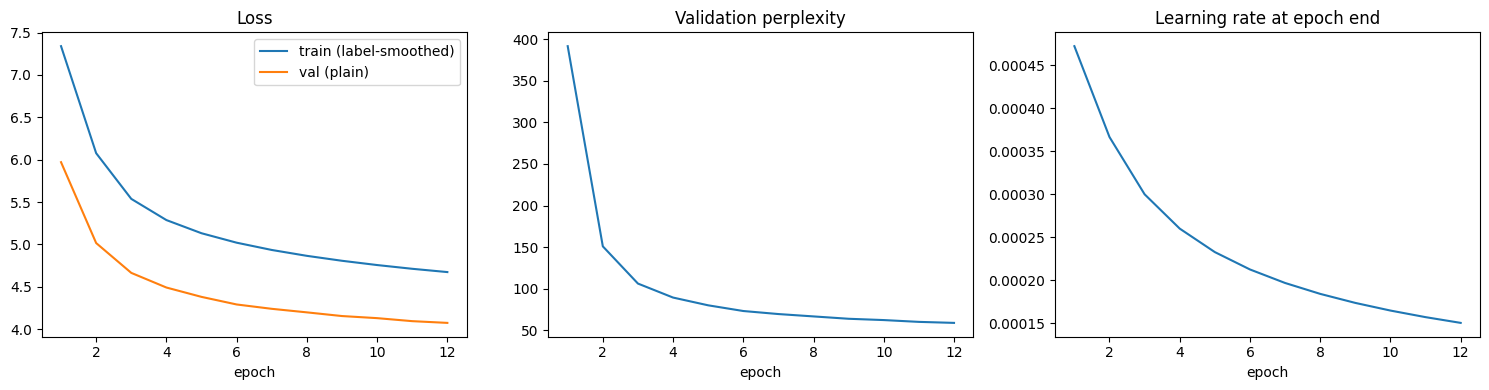

In [36]:
# loss curves
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ep = range(1, len(history["train_loss"]) + 1)

ax[0].plot(ep, history["train_loss"], label="train (label-smoothed)")
ax[0].plot(ep, history["val_loss"], label="val (plain)")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(ep, history["val_ppl"]); ax[1].set_title("Validation perplexity"); ax[1].set_xlabel("epoch")
ax[2].plot(ep, history["lr"]); ax[2].set_title("Learning rate at epoch end"); ax[2].set_xlabel("epoch")
plt.tight_layout(); plt.show()

In [37]:
# load the best checkpoint
ckpt = torch.load(os.path.join(CKPT_DIR, "best.pt"), map_location=device)
net.load_state_dict(ckpt["model"])
net.eval()
print("Loaded best.pt from epoch:", ckpt["epochs_done"], "| best val loss:", round(ckpt["best_val"], 3))

Loaded best.pt from epoch: 12 | best val loss: 4.075


In [38]:
# the generator and the lead-3 helper
@torch.no_grad()
def summarize_ids(src_ids, beam=4, alpha=0.8, no_repeat=3, min_len=25, max_new=MAX_TGT - 2):
    net.eval()
    ids = [BOS] + [int(x) for x in src_ids] + [EOS]
    src = torch.tensor([ids], device=device)
    src_mask = make_src_mask(src, PAD)
    memory = net.encode(src, src_mask)                       # the article is encoded once

    beams, finished = [([BOS], 0.0)], []
    for step in range(max_new):
        seqs = torch.tensor([b[0] for b in beams], device=device)
        nb = seqs.size(0)
        logits = net.decode(seqs, memory.expand(nb, -1, -1), src_mask.expand(nb, -1, -1, -1),
                            make_tgt_mask(seqs, PAD))
        logp = F.log_softmax(logits[:, -1].float(), dim=-1)
        logp[:, PAD] = -1e9
        logp[:, BOS] = -1e9
        if step < min_len:
            logp[:, EOS] = -1e9                              # too early to stop
        if no_repeat > 1:                                    # ban tokens that would repeat an n-gram
            for bi, (toks, _) in enumerate(beams):
                if len(toks) >= no_repeat:
                    prefix = tuple(toks[-(no_repeat - 1):])
                    banned = [toks[i + no_repeat - 1] for i in range(len(toks) - no_repeat + 1)
                              if tuple(toks[i:i + no_repeat - 1]) == prefix]
                    if banned:
                        logp[bi, banned] = -1e9

        cands = []
        for bi, (toks, score) in enumerate(beams):
            top_lp, top_id = logp[bi].topk(beam)
            for lp, tid in zip(top_lp.tolist(), top_id.tolist()):
                cands.append((toks + [tid], score + lp))
        cands.sort(key=lambda x: x[1], reverse=True)

        beams = []
        for toks, score in cands:
            if toks[-1] == EOS:
                finished.append((toks, score))
            else:
                beams.append((toks, score))
            if len(beams) == beam:
                break
        if not beams or len(finished) >= beam:
            break

    if not finished:
        finished = beams
    best = max(finished, key=lambda it: it[1] / (((5 + len(it[0]) - 1) / 6) ** alpha))
    return sp.decode([t for t in best[0][1:] if t != EOS])


sent_split = re.compile(r"(?<=[.!?])\s+")

def lead3(article):
    return " ".join(sent_split.split(article.strip())[:3])

print("generator ready")

generator ready


In [39]:
# compare methods on test articles
for i in [0, 5, 12, 40]:
    print("=" * 100)
    print("ARTICLE  :", test_df["article"].iloc[i][:350], "...")
    print("REFERENCE:", test_df["summary"].iloc[i])
    print("LEAD-3   :", lead3(test_df["article"].iloc[i]))
    print("GREEDY (plain)        :", summarize_ids(test_src[i], beam=1, no_repeat=0, min_len=0))
    print("GREEDY + no-repeat    :", summarize_ids(test_src[i], beam=1, no_repeat=3, min_len=25))
    print("BEAM 4 + no-repeat    :", summarize_ids(test_src[i], beam=4, no_repeat=3, min_len=25))
    print()

ARTICLE  : The Palestinian Authority officially became the 123rd member of the International Criminal Court on Wednesday, a step that gives the court jurisdiction over alleged crimes in Palestinian territories. The formal accession was marked with a ceremony at The Hague, in the Netherlands, where the court is based. The Palestinians signed the ICC's founding ...
REFERENCE: Membership gives the ICC jurisdiction over alleged crimes committed in Palestinian territories since last June. Israel and the United States opposed the move, which could open the door to war crimes investigations against Israelis.
LEAD-3   : The Palestinian Authority officially became the 123rd member of the International Criminal Court on Wednesday, a step that gives the court jurisdiction over alleged crimes in Palestinian territories. The formal accession was marked with a ceremony at The Hague, in the Netherlands, where the court is based. The Palestinians signed the ICC's founding Rome Statute in January, when

In [40]:
# effect of the settings on one side
i = 12
print("REFERENCE:", test_df["summary"].iloc[i], "\n")
for beam, alpha, nr, ml in [(1, 0.8, 3, 25), (4, 0.6, 3, 25), (4, 1.0, 3, 25),
                            (4, 1.5, 3, 25), (4, 0.8, 4, 25), (4, 0.8, 3, 10), (8, 0.8, 3, 25)]:
    out = summarize_ids(test_src[i], beam=beam, alpha=alpha, no_repeat=nr, min_len=ml)
    print(f"beam={beam} alpha={alpha} no_repeat={nr} min_len={ml}  [{len(out.split())} words]")
    print("  ", out, "\n")

REFERENCE: Museum: Anne Frank died earlier than previously believed. Researchers re-examined archives and testimonies of survivors. Anne and older sister Margot Frank are believed to have died in February 1945. 

beam=1 alpha=0.8 no_repeat=3 min_len=25  [32 words]
   Anne Bergenen, 31, was imprisoned for the death of Frank Holocaust. She was found in a secret camp at the age of 15. She was released from the camp in March 1945. 

beam=4 alpha=0.6 no_repeat=3 min_len=25  [24 words]
   Anne Bergenen, 31, and Frank Frank Holocaust, 31, were imprisoned in 1945. They were found at least seven weeks earlier in the last month. 

beam=4 alpha=1.0 no_repeat=3 min_len=25  [24 words]
   Anne Bergenen, 31, and Frank Frank Holocaust, 31, were imprisoned in 1945. They were found at least seven weeks earlier in the last month. 

beam=4 alpha=1.5 no_repeat=3 min_len=25  [35 words]
   Anne Bergenen, 31, and Frank Frank Holocaust, 31, were imprisoned in 1945. They were found at least seven weeks earlier 

In [41]:
# diagnostic on 100 test articles
def ngrams(words, n=3):
    return [tuple(words[k:k + n]) for k in range(len(words) - n + 1)]

def summary_stats(summaries, articles):
    novel, rep, lens = [], [], []
    for s, a in zip(summaries, articles):
        ws = s.lower().split()
        art_grams = set(ngrams(a.lower().split()))
        g = ngrams(ws)
        lens.append(len(ws))
        if g:
            novel.append(np.mean([x not in art_grams for x in g]))
            rep.append(len(g) != len(set(g)))
    return np.mean(lens), np.mean(novel) * 100, np.mean(rep) * 100

idx = list(range(0, 1000, 10))                      # 100 test articles spread over the test set
arts = [test_df["article"].iloc[i] for i in idx]
refs = [test_df["summary"].iloc[i] for i in idx]

t0 = time.time()
outs = [summarize_ids(test_src[i], beam=1, no_repeat=3, min_len=25) for i in idx]
print(f"Generated 100 summaries in {time.time() - t0:.0f}s\n")

print(f"{'':12s} {'avg words':>10} {'new 3-grams':>12} {'repeats':>9}")
for name, texts in [("reference", refs), ("model", outs), ("lead-3", [lead3(a) for a in arts])]:
    L, nv, rp = summary_stats(texts, arts)
    print(f"{name:12s} {L:>10.1f} {nv:>11.1f}% {rp:>8.1f}%")

Generated 100 summaries in 59s

              avg words  new 3-grams   repeats
reference          32.4        77.6%      0.0%
model              31.3        94.6%      5.0%
lead-3             63.8         0.0%     11.0%


In [1]:
# libraries, tokenizer, model, test data
import os, re, sys, time, json, math, gc
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import sentencepiece as spm

BASE_DIR      = os.getcwd()
PROCESSED_DIR = os.path.join(BASE_DIR, "processed_data")
TOKENIZER_DIR = os.path.join(BASE_DIR, "tokenizer")
CKPT_DIR      = os.path.join(BASE_DIR, "checkpoints")
assert os.path.exists(os.path.join(CKPT_DIR, "best.pt")), f"best.pt not found. Notebook folder is: {BASE_DIR}"

# tokenizer
sp = spm.SentencePieceProcessor(model_file=os.path.join(TOKENIZER_DIR, "bpe.model"))
VOCAB_SIZE = sp.get_piece_size()
PAD, UNK, BOS, EOS = sp.pad_id(), sp.unk_id(), sp.bos_id(), sp.eos_id()

# model (model.py must be in this folder)
sys.path.insert(0, BASE_DIR)
from model import Transformer, make_src_mask, make_tgt_mask

device  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ckpt    = torch.load(os.path.join(CKPT_DIR, "best.pt"), map_location=device)
MODEL_CFG, MAX_SRC, MAX_TGT = ckpt["model_cfg"], ckpt["max_src"], ckpt["max_tgt"]

net = Transformer(**MODEL_CFG).to(device)
net.load_state_dict(ckpt["model"])
net.eval()

# test data (text and token ids)
test_df  = pd.read_parquet(os.path.join(PROCESSED_DIR, "test.parquet"))
tok      = pd.read_parquet(os.path.join(PROCESSED_DIR, "test_tok.parquet"))
test_src = tok["src_ids"].tolist()
test_tgt = tok["tgt_ids"].tolist()
assert len(test_df) == len(test_src)

print(f"Loaded best.pt from epoch {ckpt['epochs_done']} (val loss {ckpt['best_val']:.3f}) on {device}")
print(f"Test articles: {len(test_df):,} | MAX_SRC {MAX_SRC} | MAX_TGT {MAX_TGT} | vocab {VOCAB_SIZE}")

Loaded best.pt from epoch 13 (val loss 4.049) on cuda
Test articles: 11,463 | MAX_SRC 400 | MAX_TGT 110 | vocab 16000


In [2]:
# beam-search generator and lead-3
@torch.no_grad()
def summarize_ids(src_ids, beam=4, alpha=0.8, no_repeat=3, min_len=25, max_new=None):
    max_new = max_new or (MAX_TGT - 2)
    net.eval()
    ids = [BOS] + [int(x) for x in src_ids] + [EOS]
    src = torch.tensor([ids], device=device)
    src_mask = make_src_mask(src, PAD)
    memory = net.encode(src, src_mask)

    beams, finished = [([BOS], 0.0)], []
    for step in range(max_new):
        seqs = torch.tensor([b[0] for b in beams], device=device)
        nb = seqs.size(0)
        logits = net.decode(seqs, memory.expand(nb, -1, -1), src_mask.expand(nb, -1, -1, -1),
                            make_tgt_mask(seqs, PAD))
        logp = F.log_softmax(logits[:, -1].float(), dim=-1)
        logp[:, PAD] = -1e9
        logp[:, BOS] = -1e9
        if step < min_len:
            logp[:, EOS] = -1e9
        if no_repeat > 1:
            for bi, (toks, _) in enumerate(beams):
                if len(toks) >= no_repeat:
                    prefix = tuple(toks[-(no_repeat - 1):])
                    banned = [toks[i + no_repeat - 1] for i in range(len(toks) - no_repeat + 1)
                              if tuple(toks[i:i + no_repeat - 1]) == prefix]
                    if banned:
                        logp[bi, banned] = -1e9

        cands = []
        for bi, (toks, score) in enumerate(beams):
            top_lp, top_id = logp[bi].topk(beam)
            for lp, tid in zip(top_lp.tolist(), top_id.tolist()):
                cands.append((toks + [tid], score + lp))
        cands.sort(key=lambda x: x[1], reverse=True)

        beams = []
        for toks, score in cands:
            if toks[-1] == EOS:
                finished.append((toks, score))
            else:
                beams.append((toks, score))
            if len(beams) == beam:
                break
        if not beams or len(finished) >= beam:
            break

    if not finished:
        finished = beams
    best = max(finished, key=lambda it: it[1] / (((5 + len(it[0]) - 1) / 6) ** alpha))
    return sp.decode([t for t in best[0][1:] if t != EOS])


sent_split = re.compile(r"(?<=[.!?])\s+")

def lead3(article):
    return " ".join(sent_split.split(article.strip())[:3])

print("generator ready")

generator ready


In [3]:
# roughe setup
%pip install rouge-score -q
from rouge_score import rouge_scorer

scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)

def rouge_avg(preds, refs):
    r1 = r2 = rl = 0.0
    for p, r in zip(preds, refs):
        s = scorer.score(r, p)                       # (reference, prediction)
        r1 += s["rouge1"].fmeasure; r2 += s["rouge2"].fmeasure; rl += s["rougeL"].fmeasure
    n = len(preds)
    return 100 * r1 / n, 100 * r2 / n, 100 * rl / n

print("ROUGE ready")


[notice] A new release of pip is available: 22.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
ROUGE ready


In [4]:
# check where the cnn-style articles end
ref_words = test_df["summary"].str.split().str.len()
art_words = test_df["article"].str.split().str.len()

print("rows           mean reference words   mean article words")
for st in range(0, 2200, 200):
    b = slice(st, st + 200)
    print(f"{st:>5}-{st + 199:<5}    {ref_words.iloc[b].mean():>14.1f}   {art_words.iloc[b].mean():>16.1f}")
print(f"{'2200+':<12}    {ref_words.iloc[2200:].mean():>14.1f}   {art_words.iloc[2200:].mean():>16.1f}")
print("\nIf the reference length jumps up around row 1100, the first rows are the CNN-style articles.")

rows           mean reference words   mean article words
    0-199                32.4              554.8
  200-399                32.4              541.5
  400-599                31.8              651.2
  600-799                31.2              653.5
  800-999                32.9              712.8
 1000-1199               41.8              568.1
 1200-1399               44.5              464.1
 1400-1599               46.8              549.5
 1600-1799               45.8              542.1
 1800-1999               45.6              508.5
 2000-2199               48.5              560.8
2200+                     53.7              708.5

If the reference length jumps up around row 1100, the first rows are the CNN-style articles.


In [5]:
# batched greedy generator and genration on the sample
@torch.no_grad()
def greedy_batch(src_list, batch_size=48, no_repeat=3, min_len=25, max_new=None):
    max_new = max_new or (MAX_TGT - 2)
    net.eval()
    order = sorted(range(len(src_list)), key=lambda i: len(src_list[i]))
    results = [None] * len(src_list)

    for st in range(0, len(order), batch_size):
        idx = order[st:st + batch_size]
        seqs = [[BOS] + [int(x) for x in src_list[i]] + [EOS] for i in idx]
        L = max(len(s) for s in seqs)
        src = torch.tensor([s + [PAD] * (L - len(s)) for s in seqs], device=device)
        src_mask = make_src_mask(src, PAD)
        memory = net.encode(src, src_mask)

        B = len(idx)
        ys = torch.full((B, 1), BOS, dtype=torch.long, device=device)
        hist = [[BOS] for _ in range(B)]
        done = [False] * B

        for step in range(max_new):
            logits = net.decode(ys, memory, src_mask, make_tgt_mask(ys, PAD))
            logp = F.log_softmax(logits[:, -1].float(), dim=-1)
            logp[:, PAD] = -1e9
            logp[:, BOS] = -1e9
            if step < min_len:
                logp[:, EOS] = -1e9
            if no_repeat > 1:
                for b in range(B):
                    toks = hist[b]
                    if done[b] or len(toks) < no_repeat:
                        continue
                    prefix = tuple(toks[-(no_repeat - 1):])
                    banned = [toks[k + no_repeat - 1] for k in range(len(toks) - no_repeat + 1)
                              if tuple(toks[k:k + no_repeat - 1]) == prefix]
                    if banned:
                        logp[b, banned] = -1e9

            nxt = logp.argmax(-1).tolist()
            for b in range(B):
                if done[b]:
                    nxt[b] = PAD
                else:
                    hist[b].append(nxt[b])
                    if nxt[b] == EOS:
                        done[b] = True
            ys = torch.cat([ys, torch.tensor(nxt, device=device).unsqueeze(1)], dim=1)
            if all(done):
                break

        for b, i in enumerate(idx):
            results[i] = sp.decode([t for t in hist[b][1:] if t != EOS])
    return results


CNN_N  = 1100                                    # approximate number of CNN-style rows at the start of the test split
SAMPLE = list(range(0, len(test_df), 11))
pos    = {i: k for k, i in enumerate(SAMPLE)}

t0 = time.time()
model_out = greedy_batch([test_src[i] for i in SAMPLE])
print(f"Generated {len(SAMPLE)} summaries in {(time.time() - t0) / 60:.1f} min")

Generated 1043 summaries in 1.9 min


In [6]:
# roughe table (model vs lead-3, by style)
groups = {
    "all":                    SAMPLE,
    "DailyMail-style (1100+)": [i for i in SAMPLE if i >= CNN_N],
    "CNN-style (<1100)":       [i for i in SAMPLE if i < CNN_N],
}
lead_out = {i: lead3(test_df["article"].iloc[i]) for i in SAMPLE}

rows = []
for gname, idxs in groups.items():
    refs = [test_df["summary"].iloc[i] for i in idxs]
    for sname, outs in [("Lead-3", [lead_out[i] for i in idxs]),
                        ("Model (greedy)", [model_out[pos[i]] for i in idxs])]:
        r1, r2, rl = rouge_avg(outs, refs)
        rows.append({"group": gname, "system": sname, "n": len(idxs), "ROUGE-1": r1, "ROUGE-2": r2,
                     "ROUGE-L": rl, "avg words": np.mean([len(o.split()) for o in outs])})
print(pd.DataFrame(rows).round(1).to_string(index=False))

# Lead-3 on the complete test set, for context
t0 = time.time()
all_lead = [lead3(a) for a in test_df["article"]]
r1, r2, rl = rouge_avg(all_lead, test_df["summary"].tolist())
print(f"\nLead-3 on the FULL test set ({len(test_df):,} articles): R1 {r1:.1f} | R2 {r2:.1f} | R-L {rl:.1f}   ({time.time() - t0:.0f}s)")

                  group         system    n  ROUGE-1  ROUGE-2  ROUGE-L  avg words
                    all         Lead-3 1043     40.2     17.7     25.4       75.7
                    all Model (greedy) 1043     28.9      6.4     19.0       32.3
DailyMail-style (1100+)         Lead-3  943     41.3     18.4     25.9       76.9
DailyMail-style (1100+) Model (greedy)  943     29.4      6.6     19.2       32.5
      CNN-style (<1100)         Lead-3  100     29.7     11.0     20.3       65.2
      CNN-style (<1100) Model (greedy)  100     24.6      5.0     16.8       30.1

Lead-3 on the FULL test set (11,463 articles): R1 40.0 | R2 17.4 | R-L 24.9   (46s)


In [7]:
# faithfulness: are the names and numbers real?
ent_re = re.compile(r"\b[A-Z][A-Za-z'’-]+\b|\b\d[\d,.]*\b")

def entities(text):
    out = []
    for m in ent_re.finditer(text):
        w = m.group()
        if w[0].isalpha() and (m.start() == 0 or text[max(0, m.start() - 2):m.start()] in (". ", "! ", "? ")):
            continue                                    # sentence-initial words are not names
        out.append(w.strip(".,"))
    return out

def entity_precision(summaries, visible):
    hit = tot = 0
    for s, a in zip(summaries, visible):
        for e in entities(s):
            tot += 1
            hit += e in a
    return 100 * hit / max(tot, 1)

def ngrams(ws, n=3):
    return [tuple(ws[k:k + n]) for k in range(len(ws) - n + 1)]

visible = [sp.decode([int(x) for x in test_src[i]]) for i in SAMPLE]       # what the model could see
refs    = [test_df["summary"].iloc[i] for i in SAMPLE]

print(f"{'':16s} {'names/numbers found in article':>32} {'new 3-grams':>12} {'repeats':>9}")
for name, texts in [("reference", refs), ("model", model_out), ("lead-3", [lead_out[i] for i in SAMPLE])]:
    ep = entity_precision(texts, visible)
    novel, rep = [], []
    for s, a in zip(texts, visible):
        g = ngrams(s.lower().split()); ag = set(ngrams(a.lower().split()))
        if g:
            novel.append(np.mean([x not in ag for x in g])); rep.append(len(g) != len(set(g)))
    print(f"{name:16s} {ep:>31.1f}% {np.mean(novel) * 100:>11.1f}% {np.mean(rep) * 100:>8.1f}%")

                   names/numbers found in article  new 3-grams   repeats
reference                                   84.5%        78.9%      5.6%
model                                       82.2%        93.9%      4.9%
lead-3                                     100.0%         0.0%     16.7%


In [8]:
# side-by-sde examples from both styles
show = [i for i in SAMPLE if i >= CNN_N][5:8] + [i for i in SAMPLE if i < CNN_N][3:5]
for i in show:
    style = "CNN-style" if i < CNN_N else "DailyMail-style"
    print("=" * 100)
    print(f"[{style}] ARTICLE:", test_df["article"].iloc[i][:300], "...")
    print("REFERENCE:", test_df["summary"].iloc[i])
    print("MODEL    :", model_out[pos[i]])
    print()

[DailyMail-style] ARTICLE: Bayern Munich will be without versatile left-back David Alaba for the closing stages of the season after he was ruled out for around seven weeks with a torn knee ligament. Alaba, out for three months earlier this season after a partial ligament tear in his right knee, was injured while playing for A ...
REFERENCE: Austria drew 1-1 against Bosnia-Herzegovina on Tuesday night. David Alaba picked up a knee injury during the first half of the game. Alaba was out for three months earlier this season after he suffered a partial ligament tear in his right knee.
MODEL    : David Bosnigo will be playing for the season for the first time since the season. Bayern Munich's Bayern Munich star has been ruled out for the last season.

[DailyMail-style] ARTICLE: Troubled footballer Clarke Carlisle has revealed he has split from his wife as he continues to battle with depression following his failed suicide attempt. The former Premier League defender said he had 'moved out of

In [9]:
# beam searches vs greedy on 60 dailymail-style articles
sub = [i for i in SAMPLE if i >= CNN_N][::16][:60]
refs_sub = [test_df["summary"].iloc[i] for i in sub]

t0 = time.time()
beam_out = [summarize_ids(test_src[i], beam=4, alpha=0.8, no_repeat=3, min_len=25) for i in sub]
print(f"Beam search on {len(sub)} articles took {time.time() - t0:.0f}s")

for name, outs in [("greedy", [model_out[pos[i]] for i in sub]), ("beam 4", beam_out)]:
    r1, r2, rl = rouge_avg(outs, refs_sub)
    print(f"{name:7s} R1 {r1:5.1f} | R2 {r2:5.1f} | R-L {rl:5.1f} | avg words {np.mean([len(o.split()) for o in outs]):.1f}")

Beam search on 59 articles took 47s
greedy  R1  28.5 | R2   6.3 | R-L  19.1 | avg words 32.5
beam 4  R1  27.9 | R2   6.9 | R-L  18.6 | avg words 27.4


In [10]:

dm = [i for i in SAMPLE if i >= CNN_N][:300]
refs = [test_df["summary"].iloc[i] for i in dm]
for ml in [25, 40, 55]:
    outs = greedy_batch([test_src[i] for i in dm], min_len=ml)
    r1, r2, rl = rouge_avg(outs, refs)
    print(f"min_len {ml:>2}: R1 {r1:5.1f} | R2 {r2:5.1f} | R-L {rl:5.1f} | avg words {np.mean([len(o.split()) for o in outs]):.1f}")

min_len 25: R1  29.7 | R2   7.4 | R-L  19.8 | avg words 32.1
min_len 40: R1  30.1 | R2   7.5 | R-L  19.8 | avg words 36.9
min_len 55: R1  30.0 | R2   7.5 | R-L  19.6 | avg words 48.6


In [11]:
# Export the slim model
os.makedirs("exports", exist_ok=True)
ck = torch.load(os.path.join(CKPT_DIR, "best.pt"), map_location="cpu")
out_path = os.path.join("exports", "summarizer_inference.pt")

torch.save({
    "model": ck["model"], "model_cfg": ck["model_cfg"],
    "max_src": ck["max_src"], "max_tgt": ck["max_tgt"],
    "info": {"epochs": ck["epochs_done"], "val_loss": round(ck["best_val"], 3), "train_articles": 88127,
             "rouge1": 28.9, "rouge2": 6.4, "rougeL": 19.0,
             "lead3_rouge1": 40.2, "lead3_rouge2": 17.7, "lead3_rougeL": 25.4,
             "eval_articles": 1043},
}, out_path)

print("Saved:", os.path.abspath(out_path), f"({os.path.getsize(out_path) / 1e6:.0f} MB)")
print("Info :", torch.load(out_path, map_location="cpu")["info"])

Saved: e:\Pyhton code\Deep Learning\Natural Language Processing (NLP)\article text summarization\exports\summarizer_inference.pt (46 MB)
Info : {'epochs': 13, 'val_loss': 4.049, 'train_articles': 88127, 'rouge1': 28.9, 'rouge2': 6.4, 'rougeL': 19.0, 'lead3_rouge1': 40.2, 'lead3_rouge2': 17.7, 'lead3_rougeL': 25.4, 'eval_articles': 1043}


In [14]:
# %%
import os, re

def fix_file(path, varname):
    src = open(path, encoding="utf-8").read()
    m = re.search(varname + r"\s*=\s*r'''(.*?)'''", src, re.S)
    if m:
        with open(path, "w", encoding="utf-8") as f:
            f.write(m.group(1).lstrip())
        print(f"Fixed   {path}")
    else:
        print(f"No wrapper found in {path} (already clean, or a different problem)")
    lines = open(path, encoding="utf-8").read().splitlines()
    print(f"        lines: {len(lines)} | first line: {lines[0]!r} | last line: {lines[-1]!r}\n")

fix_file("app.py", "app_code")
fix_file("summarizer.py", "summarizer_code")

No wrapper found in app.py (already clean, or a different problem)
        lines: 117 | first line: 'import os' | last line: '    )'

No wrapper found in summarizer.py (already clean, or a different problem)
        lines: 95 | first line: 'import os, re' | last line: '        }'



In [15]:
# test the module in the notebook
import importlib
sys.path.insert(0, os.getcwd())
import summarizer
importlib.reload(summarizer)

sm = summarizer.Summarizer()
print("Device:", sm.device, "| params:", f"{sm.n_params:,}", "| max_src:", sm.max_src, "| max_tgt:", sm.max_tgt, "\n")

demo = ("The city council of Riverton voted on Tuesday night to approve a new plan to build a bike lane network "
        "across the downtown area. The plan, which passed by seven votes to two, will add 22 miles of protected "
        "lanes over the next three years at a cost of 14 million dollars. Mayor Helen Carter said the project "
        "would make streets safer and reduce traffic. Opponents argued that the lanes would remove parking spaces "
        "and hurt small businesses. Construction is expected to begin in March.")

for name, art in [("fictional demo", demo), ("test article 3000", test_df["article"].iloc[3000])]:
    t0 = time.time()
    res = sm.summarize(art)
    print(f"[{name}]  {time.time() - t0:.2f}s | words used {res['words_used']} of {res['words_total']} | truncated: {res['truncated']}")
    print("  MODEL :", res["summary"])
    print("  LEAD-3:", res["lead3"][:250], "...\n")

Device: cuda | params: 11,469,824 | max_src: 400 | max_tgt: 110 

[fictional demo]  0.94s | words used 85 of 85 | truncated: False
  MODEL : The city council voted to approve seven-hour plan to reduce lanes. The plan would be protected by 14 miles across the next two years. The plans would be passed to the next three years.
  LEAD-3: The city council of Riverton voted on Tuesday night to approve a new plan to build a bike lane network across the downtown area. The plan, which passed by seven votes to two, will add 22 miles of protected lanes over the next three years at a cost of ...

[test article 3000]  0.63s | words used 319 of 449 | truncated: True
  MODEL : Lukas Podolski has joined Arsenal in January. The 29-year-old is currently in the Premier League. Arsenal are currently on loan at the Emirates.
  LEAD-3: Lukas Podolski insists he is prepared to fight for his place at Arsenal when he arrives back at the club in the summer. The German World Cup winner is currently on loan at In

In [13]:
# %%
needed = ["model.py", "summarizer.py", "app.py", "config.json",
          os.path.join("tokenizer", "bpe.model"), os.path.join("exports", "summarizer_inference.pt")]
for f in needed:
    print(("OK       " if os.path.exists(f) else "MISSING  ") + f)
print("\napp.py first line:", open("app.py", encoding="utf-8").read().splitlines()[0], "| should be: import os")

OK       model.py
OK       summarizer.py
OK       app.py
OK       config.json
OK       tokenizer\bpe.model
OK       exports\summarizer_inference.pt

app.py first line: # %% | should be: import os


In [2]:
# test
import os, sys, importlib, webbrowser, pathlib
sys.path.insert(0, os.getcwd())
import summarizer, xray_sum
importlib.reload(summarizer); importlib.reload(xray_sum)

sm = summarizer.Summarizer()
ARTICLE = ("The city council of Riverton voted on Tuesday night to approve a new plan to build a bike lane network "
           "across the downtown area. The plan, which passed by seven votes to two, will add 22 miles of protected "
           "lanes over the next three years at a cost of 14 million dollars. Mayor Helen Carter said the project "
           "would make streets safer and reduce traffic. Supporters, including cycling groups and local shop owners, "
           "spoke in favour of the plan at the meeting. Opponents argued that the lanes would remove parking spaces "
           "and hurt small businesses. Construction is expected to begin in March, starting with the main shopping "
           "street. The council will review the results after the first year and decide whether to expand the "
           "network to the suburbs.")          # replace with any real news article

trace = xray_sum.build_trace(sm, ARTICLE)
print("Summary    :", trace["summary"])
print("Words read :", trace["n_read"], "of", trace["n_words"], "| steps:", len(trace["steps"]))
print("Stats      :", trace["stats"])

os.makedirs("outputs", exist_ok=True)
out = os.path.abspath("outputs/xray_sum_demo.html")
open(out, "w", encoding="utf-8").write(xray_sum.render_html(trace))
webbrowser.open(pathlib.Path(out).as_uri())

ModuleNotFoundError: No module named 'xray_sum'

In [3]:
# %%
import os, shutil

proj = os.getcwd()                      # must be the 'article text summarization' folder
print("Project folder:", proj)

home = os.path.expanduser("~")
search = [os.path.join(home, "Downloads"), os.path.join(home, "Desktop"), os.path.join(home, "Documents")]
for name in ["xray_sum.py", "xray_sum_template.html"]:
    if os.path.exists(os.path.join(proj, name)):
        print("Already here:", name)
        continue
    found = None
    for base in search:
        for root, _, files in os.walk(base):
            if name in files:
                found = os.path.join(root, name)
                break
        if found:
            break
    if found:
        shutil.copy(found, os.path.join(proj, name))
        print("Copied", name, "from", found)
    else:
        print("NOT FOUND:", name, "-> download it again and save it into the project folder by hand")

print("\nFiles in the folder:", sorted(f for f in os.listdir(proj) if f.startswith("xray") or f in ("app.py", "model.py", "summarizer.py")))

Project folder: e:\Pyhton code\Deep Learning\Natural Language Processing (NLP)\article text summarization
NOT FOUND: xray_sum.py -> download it again and save it into the project folder by hand
NOT FOUND: xray_sum_template.html -> download it again and save it into the project folder by hand

Files in the folder: ['app.py', 'model.py', 'summarizer.py', 'xray_sum.html']


In [4]:
# %%
import os

# ---------- 1) the animation page: fix the file name ----------
if os.path.exists("xray_sum.html") and not os.path.exists("xray_sum_template.html"):
    txt = open("xray_sum.html", encoding="utf-8").read()
    if "__DATA__" in txt:
        os.rename("xray_sum.html", "xray_sum_template.html")
        print("Renamed xray_sum.html -> xray_sum_template.html")
    else:
        print("xray_sum.html does NOT contain the animation page (no __DATA__ marker). Download xray_sum_template.html from the chat card and save it here.")

# ---------- 2) the Python module ----------
code = r'''
import os, re, json
import numpy as np
import torch
import torch.nn.functional as F
import streamlit as st
import streamlit.components.v1 as components
from model import MultiHeadAttention, make_src_mask, make_tgt_mask

_HERE = os.path.dirname(os.path.abspath(__file__))
NODES, TOPK_LINKS, TOPK_LOOK = 8, 6, 12


def _group(sp, ids):
    """Group SentencePiece ids into words: returns (word texts, word index of each token, token indices per word)."""
    groups = []
    for i, t in enumerate(ids):
        if i == 0 or sp.id_to_piece(int(t)).startswith("▁"):
            groups.append([])
        groups[-1].append(i)
    words = [sp.decode([int(ids[j]) for j in g]).strip() for g in groups]
    wof = np.zeros(len(ids), dtype=np.int64)
    for w, g in enumerate(groups):
        wof[g] = w
    return words, wof, groups


def _norm(w):
    return re.sub(r"[\W_]+", "", re.sub(r"['’]s$", "", w.lower()))


def _show(sp, t, eos):
    if t == eos:
        return "end"
    p = sp.id_to_piece(int(t))
    return "?" if p.startswith("<0x") else (p.replace("▁", "") or "·")


def _pool(x):
    """(n, 256) -> (n, NODES): the strongest value inside each group of dimensions."""
    a = x.float().cpu().numpy()
    cols = [a[:, g][np.arange(len(a)), np.abs(a[:, g]).argmax(1)] for g in np.array_split(np.arange(a.shape[1]), NODES)]
    return np.stack(cols, 1)


def build_trace(sm, article, min_len=25, no_repeat=3):
    """Run one article through the Summarizer's model and record everything the animation shows."""
    mods = [m for m in sm.net.modules() if isinstance(m, MultiHeadAttention)]
    for m in mods:
        m.save_attn = True
    try:
        return _trace(sm, article, min_len, no_repeat)
    finally:
        for m in mods:
            m.save_attn, m.attn_weights = False, None


@torch.no_grad()
def _trace(sm, article, min_len, no_repeat):
    net, sp, dev, PAD, BOS, EOS = sm.net, sm.sp, sm.device, sm.PAD, sm.BOS, sm.EOS
    net.eval()
    clean = re.sub(r"\s+", " ", article).strip()[:4000]
    all_ids = sp.encode(clean)
    n = min(len(all_ids), sm.max_src - 2)                    # tokens the model really reads
    words, wof, groups = _group(sp, all_ids)
    nr = int(wof[n - 1]) + 1                                 # words the model reads
    M = np.zeros((nr, n), dtype=np.float32)
    M[wof[:n], np.arange(n)] = 1                             # word x token membership
    Mn = M / M.sum(1, keepdims=True)

    # ---------- the reader (encoder) ----------
    src = torch.tensor([[BOS] + all_ids[:n] + [EOS]], device=dev)
    src_mask = make_src_mask(src, PAD)
    memory = net.encode(src, src_mask)
    layers = []
    for L in net.encoder.layers:
        A = L.self_attn.attn_weights[0].float().mean(0).cpu().numpy()[1:n + 1, 1:n + 1]
        Aw = Mn @ A @ M.T                                    # word-to-word attention
        imp = Aw.mean(0)                                     # how much attention each word receives
        links = []
        for i in range(nr):
            row = Aw[i].copy()
            row[i] = 0
            links.append([[int(j), round(float(row[j]), 3)] for j in np.argsort(-row)[:TOPK_LINKS] if row[j] > 0.01])
        layers.append({"imp": np.round(imp / max(imp.max(), 1e-9), 3).tolist(), "links": links})
    mem = Mn @ _pool(memory[0, 1:n + 1])
    mem = np.round(mem / max(np.abs(mem).max(), 1e-9), 2).tolist()

    # ---------- the writer (decoder), same rules as Summarizer (greedy) ----------
    out, steps = [BOS], []
    for step in range(sm.max_tgt - 2):
        tgt = torch.tensor([out], device=dev)
        lg = net.decode(tgt, memory, src_mask, make_tgt_mask(tgt, PAD))[0, -1].float()
        raw = int(lg.argmax())
        lp = F.log_softmax(lg, -1)
        lp[PAD] = lp[BOS] = -1e9
        if step < min_len:
            lp[EOS] = -1e9
        if no_repeat > 1 and len(out) >= no_repeat:
            pre = tuple(out[-(no_repeat - 1):])
            ban = [out[i + no_repeat - 1] for i in range(len(out) - no_repeat + 1) if tuple(out[i:i + no_repeat - 1]) == pre]
            if ban:
                lp[ban] = -1e9
        nxt = int(lp.argmax())
        pv, pi = lp.exp().topk(5)
        looks = []
        for L in net.decoder.layers:
            a = L.cross_attn.attn_weights[0, :, -1, :].float().mean(0).cpu().numpy()[1:n + 1]
            aw = M @ a                                       # attention per article word
            looks.append([[int(j), round(float(aw[j]), 3)] for j in np.argsort(-aw)[:TOPK_LOOK] if aw[j] > 0.005])
        steps.append({"id": nxt, "looks": looks, "over": _show(sp, raw, EOS) if raw != nxt else "",
                      "cands": [{"w": _show(sp, i, EOS), "p": round(float(p), 3)} for p, i in zip(pv.tolist(), pi.tolist())]})
        out.append(nxt)
        if nxt == EOS:
            break

    # ---------- label every summary word: copied / new / check ----------
    ids = [s["id"] for s in steps if s["id"] != EOS]
    sw, swof, _ = _group(sp, ids)
    seen = {_norm(w) for w in words[:nr]} - {""}
    stat = []
    for k, w in enumerate(sw):
        nw, init = _norm(w), (k == 0 or sw[k - 1][-1:] in ".!?")
        if not nw:
            stat.append("none")
        elif nw in seen:
            stat.append("copied")
        elif any(c.isdigit() for c in w) or (w[:1].isupper() and not init):
            stat.append("check")
        else:
            stat.append("new")
    for k, s in enumerate(steps):
        if s["id"] == EOS:
            s["piece"], s["status"] = "", "end"
        else:
            p = sp.id_to_piece(s["id"])
            s["piece"], s["status"] = ("" if p.startswith("<0x") else p.replace("▁", " ")), stat[int(swof[k])]
        del s["id"]

    ex = [{"word": words[w], "pieces": [sp.id_to_piece(all_ids[j]).replace("▁", "") for j in g]}
          for w, g in enumerate(groups[:nr]) if len(g) > 1 and len(words[w]) > 5][:4]
    alpha = [s for s in stat if s != "none"]
    return {"words": words[:600], "n_read": nr, "n_words": len(clean.split()), "n_tok": n, "examples": ex,
            "layers": layers, "memory": mem, "steps": steps, "summary": sp.decode(ids),
            "stats": {"n": len(alpha), "copied": sum(s == "copied" for s in alpha),
                      "check": list(dict.fromkeys(w for w, s in zip(sw, stat) if s == "check"))}}


def render_html(trace):
    with open(os.path.join(_HERE, "xray_sum_template.html"), encoding="utf-8") as f:
        t = f.read()
    return t.replace("__DATA__", json.dumps(trace, ensure_ascii=False).replace("</", "<\\/"))


@st.cache_data(show_spinner="Recording what happens inside the model...")
def _page(article, _sm):
    return render_html(build_trace(_sm, article))


def streamlit_section(sm, article):
    """Add the animated 'how the model works' section to the Streamlit app."""
    st.header("How the model reads and writes")
    st.caption("A step-by-step animation of what happens inside the model for the article above.")
    if len(article.split()) < 40:
        st.info("Paste an article of at least 40 words above to see the animation.")
        return
    if st.checkbox("Show the animation for this article"):
        components.html(_page(article, sm), height=1000, scrolling=True)
'''
with open("xray_sum.py", "w", encoding="utf-8") as f:
    f.write(code.lstrip())

# ---------- 3) check ----------
print("\nFiles:", sorted(f for f in os.listdir(".") if f.startswith("xray") or f in ("app.py", "model.py", "summarizer.py")))
lines = open("xray_sum.py", encoding="utf-8").read().splitlines()
print("xray_sum.py  :", len(lines), "lines | first line:", repr(lines[0]), "| last line:", repr(lines[-1]))
print("template OK  :", os.path.exists("xray_sum_template.html") and "__DATA__" in open("xray_sum_template.html", encoding="utf-8").read())

Renamed xray_sum.html -> xray_sum_template.html

Files: ['app.py', 'model.py', 'summarizer.py', 'xray_sum.py', 'xray_sum_template.html']
xray_sum.py  : 167 lines | first line: 'import os, re, json' | last line: '        components.html(_page(article, sm), height=1000, scrolling=True)'
template OK  : True
